## Explanations via Gradient Similarity

The explanation will be formulated on the basis of the top most influential similar samples from the training set.

In [1]:
!pwd
import sys
sys.path.append('./wingbeats/')
sys.path.append('./alibi/')

/mnt/KInsektDaten/teo


In [2]:
import numpy as np
import glob
import matplotlib.pyplot as plt
from tensorflow.keras.layers.experimental.preprocessing import Rescaling
from tensorflow.keras.losses import SparseCategoricalCrossentropy, CategoricalCrossentropy

from beexplainable.beexplainable.modelling import classifiers as cls
from beexplainable.beexplainable.preprocessing import parsers as ps
from beexplainable.beexplainable.utils import metafile_readers as mr
from wingbeats import modelling as wm # for building simple classifiers
from alibi.explainers import GradientSimilarity

No module named 'nltk'


In [3]:
import tensorflow as tf
print(tf.__version__)

# Select GPU
print(tf.test.gpu_device_name())

gpus = tf.config.list_physical_devices('GPU')
print("Num GPUs available:", len(gpus))
try:
    tf.config.experimental.set_memory_growth(gpus[0], True) # don't allocate whole memory
except RuntimeError as e:
    print(e) # 'Invalid device or cannot modify virtual devices once initialized.'

2.8.1
/device:GPU:0
Num GPUs available: 1


2024-02-01 16:39:21.008712: I tensorflow/core/platform/cpu_feature_guard.cc:151] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  SSE4.1 SSE4.2 AVX AVX2 AVX512F FMA
To enable them in other operations, rebuild TensorFlow with the appropriate compiler flags.
2024-02-01 16:39:21.557274: I tensorflow/core/common_runtime/gpu/gpu_device.cc:1525] Created device /device:GPU:0 with 46962 MB memory:  -> device: 0, name: Quadro RTX 8000, pci bus id: 0000:65:00.0, compute capability: 7.5


In [4]:
metafolder = './beexplainable/metafiles/Fungi/raw/toloka_CBR/' # same metafolder for masked and masked_bbox

CLASSES_PATH = metafolder + '/classes.txt'
FUNGI_PATH = '../data/DanishFungi/DF20M_3spec/'

IMAGES_PATH_NEIGHBORS = metafolder + 'images_neighbors.txt'
IMAGES_LABELS_PATH_NEIGHBORS = metafolder + 'image_class_labels_neighbors.txt'
IMAGES_PATH_TASKS123 = metafolder + 'images_tasks123.txt'
IMAGES_LABELS_PATH_TASKS123 = metafolder + 'image_class_labels_tasks123.txt'
SOFT_PREDS = './beexplainable/metafiles/Fungi/raw/softmax_preds.npy'

MODELS_PATH  = './beexplainable/models/'

### Load Images

In [5]:
#batch_size = 64
img_height = img_width = 224

**Note**: The neighbors in the 'training set' are all the Andrena samples from images_5_cleaned.txt without the 30 samples selected for the three Toloka tasks.

In [6]:
# Read file IDs and corresponding class labels of the set of neighbors
img_dict_neigh = mr.metafile_to_dict(IMAGES_PATH_NEIGHBORS)
img_label_dict_neigh = mr.metafile_to_dict(IMAGES_LABELS_PATH_NEIGHBORS)
file_ids_neigh = list( img_dict_neigh.keys() )
y_true_neigh   = list( img_label_dict_neigh.values() )
y_true_neigh   = np.asarray(y_true_neigh, dtype = np.uint8) - 1
# Note! Labels in CUB format start at index 1, but cross entropy needs to start at 0
print(str(len(y_true_neigh)) + ' neighbors')

# Read file IDs and corresponding class labels of the samples for Toloka
img_dict_t123 = mr.metafile_to_dict(IMAGES_PATH_TASKS123)
img_label_dict_t123 = mr.metafile_to_dict(IMAGES_LABELS_PATH_TASKS123)
file_ids_t123 = list( img_dict_t123.keys() )
y_true_t123   = list( img_label_dict_t123.values() )
y_true_t123   = np.asarray(y_true_t123, dtype = np.uint8) - 1
print(str(len(y_true_t123)) + ' samples in Task 2')

610 neighbors
60 samples in Task 2


In [7]:
classes = list( mr.metafile_to_dict(CLASSES_PATH).values() )
classes

['Russula_emetica', 'Russula_paludosa', 'Russula_rosea']

In [8]:
# Get dictionary of file IDs and file names
# Convert it into a tf.StaticHashTable to be able to retrieve dictionary values during eager execution
# Alternative: tf.gather
img_lookup = tf.lookup.StaticHashTable(tf.lookup.KeyValueTensorInitializer(file_ids_neigh, list(img_dict_neigh.values())),
                                       default_value = 'No file')

# Parsing function for tf.Dataset
parse_image_lab = lambda file_id, label: (ps.parse_image(file_id, img_lookup, img_width, img_height, FUNGI_PATH),
                                          label)

2024-02-01 16:39:21.638982: I tensorflow/core/common_runtime/gpu/gpu_device.cc:1525] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 46962 MB memory:  -> device: 0, name: Quadro RTX 8000, pci bus id: 0000:65:00.0, compute capability: 7.5


In [9]:
# Conversion to tf.Dataset
train_set = ps.parse_to_dataset(file_ids_neigh, y_true_neigh, parse_image_lab)
train_set = train_set.cache().prefetch(tf.data.experimental.AUTOTUNE)

# Normalize raw images
normalization_layer = Rescaling(1./255)
train_set = train_set.map(lambda x, y: (normalization_layer(x), y))

In [10]:
# Create dataset for the test samples, too
img_lookup = tf.lookup.StaticHashTable(tf.lookup.KeyValueTensorInitializer(file_ids_t123, list(img_dict_t123.values())),
                                       default_value = 'No file')

# Parsing function for tf.Dataset
parse_image_lab = lambda file_id, label: (ps.parse_image(file_id, img_lookup, img_width, img_height, FUNGI_PATH), label)

# Conversion to tf.Dataset
test_set = ps.parse_to_dataset(file_ids_t123, y_true_t123, parse_image_lab)
test_set = test_set.cache().prefetch(tf.data.experimental.AUTOTUNE)
test_set = test_set.map(lambda x, y: (normalization_layer(x), y))

2024-02-01 16:39:22.581487: W tensorflow/core/kernels/data/cache_dataset_ops.cc:768] The calling iterator did not fully read the dataset being cached. In order to avoid unexpected truncation of the dataset, the partially cached contents of the dataset  will be discarded. This can happen if you have an input pipeline similar to `dataset.cache().take(k).repeat()`. You should use `dataset.take(k).cache().repeat()` instead.


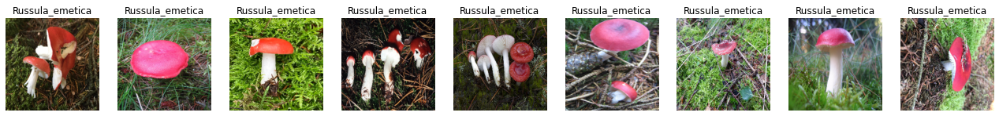

In [11]:
# Plot test samples
plt.figure(figsize = (25, 10))
num_cols = 10
with tf.device('/CPU:0'):
    i = 1
    for img, lab in test_set:
        plt.subplot(1, num_cols, i)
        plt.imshow(img)
        plt.title(classes[lab.numpy()])
        plt.axis("off")
        i += 1
        if i == 10: break
plt.show()

### Load Model

In [12]:
# Define initial training and other model parameters
epochs, drop_rate = 10, 0.5
lr, reg = 1e-3, 1e-3 # parameters optimized in HPO notebook
in_shape = (img_width, img_height, 3)

constructor, out_shape =  wm.build_simple_classifier, len(classes)
loss = 'sparse_categorical_crossentropy'
metrics = ['accuracy']

# Define whether to load fine grained backbone weights
load_pretrained_backbone = True # if False, ImageNet weights are loaded
# ResNet50 weights trained on iNat2021
# https://github.com/visipedia/newt/tree/main/benchmark
pretrained_weights_file = MODELS_PATH + 'backbones/resnet50_simclr_v1_inat20_no_top_500.h5' if load_pretrained_backbone else None

# Derive model name
input_form = 'raw' # raw, masked, bbox, masked_bbox
init = 'iNat' if load_pretrained_backbone else 'Imagenet'
model_name = 'ResNet50_' + init + '_' + input_form + '_Fungi'
print(model_name)

# The pretrained ResNet on iNat already has a GlobalAvgPooling layer
add_global_avg = False if load_pretrained_backbone else True

# Whether to retrain the backbone or not
trainable = True

ResNet50_iNat_raw_Fungi


In [13]:
# Build and compile
tf.keras.backend.clear_session()
cnn_name = 'CNN_Blocks_' + model_name

cnn = cls.CNN_ResNet50(in_shape, drop_rate, add_global_avg = add_global_avg, trainable = trainable,
                       weights_file = pretrained_weights_file, name = cnn_name)

model = constructor(in_shape, out_shape, cnn, reg,
                    input_name = 'jpg', model_name = model_name)

model.load_weights(MODELS_PATH + 'all/Fungi/' + model_name + '/' + model_name + '.h5',
                   by_name = True, skip_mismatch = True)

model.compile(tf.keras.optimizers.Adam(lr), loss = loss, metrics = metrics)

### Compute Explanations

In [14]:
def append_int(num):
    """Converts an integer into an ordinal (ex. 1 -> 1st, 2 -> 2nd, etc.)."""
    if num > 9:
        secondToLastDigit = str(num)[-2]
        if secondToLastDigit == '1':
            return 'th'
    lastDigit = num % 10
    if (lastDigit == 1):
        return 'st'
    elif (lastDigit == 2):
        return 'nd'
    elif (lastDigit == 3):
        return 'rd'
    else:
        return 'th'

def substract_mean_channel(X):
    """Subtracts the mean channels from a batch of images."""
    assert len(X.shape) == 4
    mean_channels = np.mean(X,axis=(0,1,2)).reshape(1, 1, 1, -1)
    X_mean = X - mean_channels
    return X_mean, mean_channels

In [15]:
# Alibi requires ndarrays
train_arr = np.array([img.numpy() for img, _ in train_set])
test_arr = np.array([img.numpy() for img, _ in test_set])
train_arr.shape

(610, 224, 224, 3)

In [16]:
# GradSim requires normalized channels
train_arr, mean_channels = substract_mean_channel(train_arr)
test_arr, _ = substract_mean_channel(test_arr)

In [17]:
# Initialize explainer
gsm = GradientSimilarity(model, SparseCategoricalCrossentropy(), precompute_grads=False, sim_fn='grad_cos',
                         device='gpu', verbose=True)

/mnt/KInsektDaten/teo/./alibi/alibi/explainers/similarity/grad.py:139: UserWarning: Found 106 non-trainable parameters in the model. These parameters don't have gradients and will not be included in the computation of gradient similarity. This might be because your model has layers that track statistics using non-trainable parameters such as batch normalization layers. In this case, you don't need to worry. Otherwise it's because you have set some parameters to be non-trainable and alibi is letting you know.
  warnings.warn(warning_msg)


In [18]:
# Fit explainer to training data
gsm.fit(train_arr, y_true_neigh)

GradientSimilarity(meta={
  'name': 'GradientSimilarity',
  'type': ['whitebox'],
  'explanations': ['local'],
  'params': {
              'sim_fn_name': 'grad_cos',
              'store_grads': False,
              'backend_name': 'tensorflow',
              'task_name': 'classification'}
            ,
  'version': '0.9.5dev'}
)

In [19]:
# Get most similar instances for the test set samples
expls = gsm.explain(test_arr, y_true_t123)

2024-02-01 16:39:52.238619: I tensorflow/stream_executor/cuda/cuda_dnn.cc:368] Loaded cuDNN version 8401
2024-02-01 16:39:52.727108: I tensorflow/core/platform/default/subprocess.cc:304] Start cannot spawn child process: No such file or directory
2024-02-01 16:39:52.728288: I tensorflow/core/platform/default/subprocess.cc:304] Start cannot spawn child process: No such file or directory
2024-02-01 16:39:52.728300: W tensorflow/stream_executor/gpu/asm_compiler.cc:80] Couldn't get ptxas version string: INTERNAL: Couldn't invoke ptxas --version
2024-02-01 16:39:52.729499: I tensorflow/core/platform/default/subprocess.cc:304] Start cannot spawn child process: No such file or directory
2024-02-01 16:39:52.729682: W tensorflow/stream_executor/gpu/redzone_allocator.cc:314] INTERNAL: Failed to launch ptxas
Relying on driver to perform ptx compilation. 
Modify $PATH to customize ptxas location.
This message will be only logged once.
610it [18:04,  1.78s/it]


In [20]:
# Visualize most similar instances
# Predictions for test samples were computed previously (see Uncertainties_Fungi.ipynb)
test_preds = []
loaded_soft = np.load(SOFT_PREDS)
for file_id in file_ids_t123:
    test_preds.append(np.argmax(loaded_soft[int(file_id)-1], axis=-1))

int_to_str = dict(zip([0, 1, 2], classes))
ds = []
num_most_similar = 3

for j in range(len(test_arr)):
    y_sim = y_true_neigh[expls.data['ordered_indices'][j][:num_most_similar]]
    X_sim = np.asarray(train_arr)[expls.data['ordered_indices'][j][:num_most_similar]]
    preds_sim = model(X_sim+mean_channels).numpy().argmax(axis=1)

    d = {'x': test_arr[j] + mean_channels[0],
         'y': y_true_t123[j],
         'pred': test_preds[j],
         'y_sim': y_sim,
         'preds_sim': preds_sim}
    ds.append(d)

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).
Clipping i




In [21]:
fig, axes = plt.subplots(len(ds), num_most_similar+1, figsize=(20,220), sharex=False)
for j in range(len(ds)):
    d = ds[j]
    axes[j, 0].imshow(d['x'])
    label_orig = int_to_str[d['y']]
    pred_orig = int_to_str[d['pred']]

    if j == 0:
        title_orig = "Original instance"
        axes[j, 0].set_title(f"{title_orig} \n" +
                             f"{len(title_orig) * '='} \n" +
                             f"Label: {label_orig} \n" +
                             f"Prediction: {pred_orig} ")
    else:
        axes[j, 0].set_title(f"Label: {label_orig} \n" +
                             f"Prediction: {pred_orig} ")
    axes[j, 0].axis('off')

    for i in range(num_most_similar):
        label_sim = int_to_str[d['y_sim'][i]]
        pred_sim = int_to_str[d['preds_sim'][i]]

        most_similar = train_arr[ expls.data['ordered_indices'][j][i] ] + mean_channels[0]
        axes[j, i + 1].imshow(most_similar)
        if j == 0:
            title_most_sim = f"{i+1}{append_int(i+1)} most similar instance"
            axes[j, i + 1].set_title(f"{title_most_sim} \n" +
                                     f"{len(title_most_sim) * '='} \n"+
                                     f"Label: {label_sim} \n" +
                                     f"Prediction: {pred_sim}")
        else:
            axes[j, i + 1].set_title(f"Label: {label_sim} \n" +
                                     f"Prediction: {pred_sim}")
        axes[j, i + 1].axis('off')

plt.show()

### Plot Images along with Predicted Species, Confidence and Examples (for XAI Group in Toloka)

In [ ]:
task13_paths = glob.glob('./beexplainable/toloka/fungi/images/task13_imgs/*.JPG')
for j in range(len(ds)):
    d = ds[j] # the image to be classified
    pred_orig = int_to_str[d['pred']]
    spec_pred_prob = int(np.round(np.max(loaded_soft[int(file_ids_t123[j])-1]),2)*100)

    fig = plt.figure(constrained_layout=True, figsize=(11, 11))
    axs = fig.subplot_mosaic([['MainFig', 'MainFig', 'MainFig'],['BottomLeft', 'BottomMid', 'BottomRight']],
                              gridspec_kw={'height_ratios':[5, 3]})

    axs['BottomLeft'].imshow(train_arr[ expls.data['ordered_indices'][j][0] ] + mean_channels[0])
    axs['BottomMid'].imshow(train_arr[ expls.data['ordered_indices'][j][1] ] + mean_channels[0])
    axs['BottomRight'].imshow(train_arr[ expls.data['ordered_indices'][j][2] ] + mean_channels[0])
    axs['MainFig'].imshow(d['x'])
    axs['BottomLeft'].axes.get_xaxis().set_ticks([]); axs['BottomLeft'].axes.get_yaxis().set_ticks([])
    axs['BottomMid'].axes.get_xaxis().set_ticks([]); axs['BottomMid'].axes.get_yaxis().set_ticks([])
    axs['BottomMid'].set_title('Our model is ' + str(spec_pred_prob) + '% confident\nthat this bee is ' + pred_orig.replace('_', ' ') + ' because it looks like:',
                         color='red', fontsize=25, weight='bold')
    axs['BottomRight'].axes.get_xaxis().set_ticks([]); axs['BottomRight'].axes.get_yaxis().set_ticks([])
    axs['MainFig'].axes.get_xaxis().set_ticks([]); axs['MainFig'].axes.get_yaxis().set_ticks([])

    img_id = img_dict_t123[file_ids_t123[j]].split('/')[1].split('.')[0]
    for tpath in task13_paths:
        if img_id in tpath:
            fig.savefig('./beexplainable/toloka/fungi/images/task2_examples_gradsim_imgs/' + tpath.split('/')[-1])
            break